# 01 · Exploração dos dados

Fase 2 do [`docs/workflow.md`](../docs/workflow.md): perceber os dados antes de treinar.
Os resultados e as decisões que saem daqui estão escritos em [`docs/qualidade_dados.md`](../docs/qualidade_dados.md) (secções 7 a 10).

## Como ler este notebook

Cada medição tem quatro partes:

1. **Pergunta**: o que queremos saber dos dados.
2. **Porque importa**: o que muda no modelo conforme a resposta.
3. **Código e resultado.**
4. **Como ler**: o que seria um resultado bom, mau ou estranho, e o que decidimos.

## Como correr

- No editor: abrir este ficheiro, escolher o kernel do `.venv` (canto superior direito) e carregar em "Run All".
- No terminal, a partir da raiz do projeto: `.venv/bin/jupyter nbconvert --to notebook --execute --inplace notebooks/01_exploracao.ipynb`
- As secções 7 a 9 leem os ficheiros originais (`data/processed/raw/`). A secção 10 lê a saída do `src/prepare.py` (`data/processed/treino.parquet` e `validacao.parquet`), por isso o `prepare.py` tem de ter corrido antes.

Corre sempre de cima para baixo. Se os números mudarem depois de atualizar os dados, é preciso atualizar também o `qualidade_dados.md`.

## Regra principal: não espreitar o teste

O **treino** são os contratos publicados de janeiro de 2022 a setembro de 2025, lidos de todos os ficheiros (o ficheiro de um ano é o ano de celebração, não o de publicação). A **validação** (outubro de 2025) só aparece na secção 10, para ver quantos contratos novos ficariam cobertos. O **teste** (novembro e dezembro de 2025) nem sequer é carregado: a leitura para em outubro.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
import cpv_data as cd
import prepare as pr

pd.set_option("display.max_colwidth", 90)

# Estilo dos gráficos: fundo claro, eixos discretos, uma cor por série
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#3d3d3a",
    "xtick.color": "#3d3d3a", "ytick.color": "#3d3d3a",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e1", "grid.linewidth": 0.8,
    "font.size": 11,
})
AZUL, LARANJA = "#2a78d6", "#eb6834"

## Preparação

Carregar os contratos de treino e aplicar as decisões 2 e 3 do `qualidade_dados.md`:

- sem os contratos sem CPV;
- uma só cópia de cada `idcontrato`.

`since` e `until` filtram pela data de publicação ficheiro a ficheiro: os contratos de validação e de teste nunca chegam à memória.

In [2]:
cols = ["objectoContrato", "descContrato", "CPV", "adjudicante", "DescrAcordoQuadro"]
treino = cd.load_contracts(cols, since=cd.TRAIN_START, until=cd.VAL_START)
print("Contratos publicados no período de treino:", len(treino))

treino = treino.dropna(subset=["CPV"]).drop_duplicates("idcontrato")
treino["codigo"] = cd.first_code(treino["CPV"])
treino = treino.dropna(subset=["codigo"])
treino["nivel"] = cd.code_level(treino["codigo"])

assert (cd.period(treino["data"]) == "treino").all(), "Há contratos fora do período de treino"
print("Depois das decisões 2 e 3:", len(treino), "contratos, de", treino["data"].min().date(), "a", treino["data"].max().date())

Contratos publicados no período de treino: 798276


Depois das decisões 2 e 3: 794883 contratos, de 2022-01-01 a 2025-09-30


O `assert` acima **para o notebook com um erro** se algum contrato fora do período de treino lá entrar. É uma verificação automática: se alguém mudar o código mais acima por engano, o erro aparece logo, em vez de passar despercebido.

Este número tem de bater com o funil do `prepare.py` (secção 11 do `qualidade_dados.md`, linha "Contratos de treino"). Se não bater, uma das duas partes está a aplicar regras diferentes.

## Colunas: como são os dados

**Pergunta:** que colunas existem, quão preenchidas estão e que valores têm?

**Porque importa:** é o ponto de partida para decidir que colunas podem entrar no modelo. A descrição de cada coluna, e se existe quando o técnico escolhe o CPV, está em [`docs/dados.md`](../docs/dados.md).

Com quase 800 mil contratos, as 39 colunas juntas não cabem na memória do portátil. Por isso lê-se uma coluna de cada vez. Os valores mais comuns ficam cortados a 50 caracteres.

In [3]:
todas = pd.read_parquet(cd.RAW_PARQUET / "contratos2025.parquet").columns.tolist()
ids_treino = set(treino["idcontrato"])

linhas = []
for c in todas:
    s = cd.load_contracts([c], since=cd.TRAIN_START, until=cd.VAL_START).drop_duplicates("idcontrato")
    s = s.loc[s["idcontrato"].isin(ids_treino), c]
    cheio = s.notna() & (s.str.strip() != "")
    vals = s[cheio].str.replace(r"\s+", " ", regex=True).str.strip()
    top = vals.value_counts().head(3)
    linhas.append({
        "coluna": c,
        "preenchida": cheio.mean(),
        "valores distintos": vals.nunique(),
        "valores mais comuns": "; ".join(f"{v[:50]} ({k})" for v, k in top.items()),
    })
print("Contratos de treino:", len(ids_treino))
pd.set_option("display.max_rows", 50)
pd.DataFrame(linhas).set_index("coluna").style.format({"preenchida": "{:.1%}", "valores distintos": "{:,}"})

Contratos de treino: 794883


,preenchida,valores distintos,valores mais comuns
coluna,,,
idcontrato,100.0%,"794,883",11757625 (1); 8668008 (1); 8669479 (1)
nAnuncio,14.8%,"63,871",2108/2025 (182); 2038/2022 (105); 269/2023 (89)
TipoAnuncio,14.8%,5,Anúncio de procedimento (100784); Aviso de prorrogação de prazo (7641); Anúncio de concurso urgente (4402)
idINCM,14.8%,"67,438",-1 (1231); 418613422 (182); 415808522 (102)
tipoContrato,100.0%,49,Aquisição de bens móveis (420860); Aquisição de serviços (307673); Empreitadas de obras públicas (49330)
idprocedimento,100.0%,"651,140",7474261 (444); 7468015 (397); 7462678 (395)
tipoprocedimento,100.0%,19,Ajuste Direto Regime Geral (384049); Consulta Prévia (152738); Concurso público (116180)
objectoContrato,100.0%,"569,613",MEDICAMENTOS (4937); Aquisição de serviço de viagens e alojamento – Pla (1858); Medicamentos (1506)
descContrato,100.0%,"584,340",MEDICAMENTOS (4718); Consulta Prévia ao abrigo do acordo-quadro da ESPA (2093); Aquisição de serviço de viagens e alojamento – Pla (1860)


**Como ler:**
- Uma coluna quase vazia (por exemplo `Observacoes`) dificilmente ajuda o modelo.
- Uma coluna com poucos valores distintos (`Ano`) traz pouca informação sobre o que se compra.
- Colunas com informação que só existe depois da adjudicação (o vencedor, os concorrentes, o preço final) não podem entrar, mesmo que estejam cheias: seria fuga de dados.

## 7. Colunas que ajudam os textos vagos

**Pergunta:** quando o `objectoContrato` não diz o que se compra, há outras colunas que digam?

**Porque importa:** um texto como "convite à apresentação de propostas ao abrigo do acordo-quadro..." não dá ao modelo nenhuma pista. Se outra coluna tiver a informação, juntamo-la ao texto de entrada. Só vale a pena com colunas que o técnico já conhece quando escolhe o código, senão é fuga de dados.

In [4]:
preenchido = lambda s: s.notna() & (s.str.strip() != "")
texto = cd.normalize_text(treino["objectoContrato"])
fala_de_aq = texto.str.contains("acordo") & texto.str.contains("quadro")
del texto

pd.DataFrame({
    "% preenchido em todos os contratos": [preenchido(treino[c]).mean() for c in ["DescrAcordoQuadro", "adjudicante"]],
    "% preenchido nos que falam de acordo-quadro": [preenchido(treino.loc[fala_de_aq, c]).mean() for c in ["DescrAcordoQuadro", "adjudicante"]],
}, index=["DescrAcordoQuadro", "adjudicante"]).style.format("{:.1%}")

,% preenchido em todos os contratos,% preenchido nos que falam de acordo-quadro
DescrAcordoQuadro,14.5%,96.4%
adjudicante,100.0%,100.0%


In [5]:
print("Contratos que falam de acordo-quadro:", fala_de_aq.sum(), f"({fala_de_aq.mean():.1%} do treino)")
print()
print("Descrições de acordo-quadro mais comuns:")
treino.loc[fala_de_aq, "DescrAcordoQuadro"].str[:100].value_counts().head(5)

Contratos que falam de acordo-quadro: 36381 (4.6% do treino)

Descrições de acordo-quadro mais comuns:


DescrAcordoQuadro
CP 2021/6 - Medicamentos do foro oncológico e imunomoduladores                                          5351
491/2023 - Concurso público internacional para formação do acordo quadro de medicamentos do foro onc    4316
961/2024 - Concurso público internacional para formação do acordo quadro de medicamentos diversos na    1503
671/2023 - Concurso público internacional para formação do acordo quadro de medicamentos diversos       1119
CP 2022/55 - Acordo quadro para fornecimento de medicamentos diversos                                   1064
Name: count, dtype: int64

**Como ler:**
- Se a `DescrAcordoQuadro` está quase sempre preenchida quando o texto fala de acordo-quadro, e as descrições dizem o que se compra ("...acordo quadro de medicamentos..."), resolve parte dos textos vagos. Resultado bom.
- Um resultado mau seria a coluna estar vazia nesses contratos, ou repetir o mesmo texto vago.
- **Decisão 5:** juntar a `DescrAcordoQuadro` ao texto de entrada sempre que existir. **Decisão 7:** a `adjudicante` entra só como experiência (com e sem).

## 8. O mesmo texto com códigos diferentes

**Pergunta:** quando o mesmo texto aparece várias vezes, tem sempre o mesmo código?

**Porque importa:** se não tiver, o modelo vê a mesma pergunta com respostas diferentes. Temos de decidir que resposta fica, e saber quantos contratos isso afeta.

Aqui usa-se o **texto de entrada completo** (decisão 5), construído com a mesma função do `prepare.py` (`pr.build_text`), para medir exatamente o que o modelo vai ver.

Exemplo concreto, o texto mais repetido:

In [6]:
treino["texto"] = cd.normalize_text(pr.build_text(treino))
med = treino[treino["texto"] == "medicamentos"]
print(f"'medicamentos': {len(med)} contratos, {med['adjudicante'].nunique()} entidades")
med["CPV"].str[:80].value_counts().head(6).to_frame("contratos")

'medicamentos': 6100 contratos, 7 entidades


,contratos
CPV,
"33000000-0 - Equipamento médico, medicamentos e produtos para cuidados pessoais",6095
33690000-3 - Medicamentos vários,2
24000000-4 - Produtos químicos,1
"32000000-3 - Equipamento de rádio, televisão, comunicação, telecomunicações e af",1
33600000-6 - Produtos farmacêuticos,1


No `prepare.py` esta regra aplica-se **depois** de tirar os códigos ao nível da divisão (decisão 8), por isso mede-se aqui pela mesma ordem. Com "medicamentos", isso quer dizer que os `33000000` saem primeiro e o código mais comum passa a ser outro.

In [7]:
especificos = treino[treino["nivel"] > 2]
por_par = especificos.groupby(["texto", "codigo"]).size().rename("n").reset_index()
por_texto = por_par.groupby("texto")["n"]
fora_do_mais_comum = int((por_texto.sum() - por_texto.max()).sum())
textos_em_conflito = int((por_par.groupby("texto")["codigo"].nunique() > 1).sum())

print("Contratos sem códigos ao nível da divisão:", len(especificos))
print("Textos com mais do que um código:", textos_em_conflito)
print(f"Contratos com um código diferente do mais comum do seu texto: {fora_do_mais_comum} ({fora_do_mais_comum / len(especificos):.1%})")
del especificos, por_par, por_texto

Contratos sem códigos ao nível da divisão: 645625
Textos com mais do que um código: 6849
Contratos com um código diferente do mais comum do seu texto: 14348 (2.2%)


**Como ler:**
- A percentagem de contratos fora do código mais comum é o que se perde se ficarmos só com esse código. Resultado bom: poucos por cento. Resultado mau: dezenas por cento, o que quereria dizer que o texto sozinho não chega para decidir.
- O número de contratos fora do mais comum tem de ser igual ao do funil do `prepare.py` (linha "Que seguem o código mais comum do seu texto"). A regra de desempate pode mudar *qual* código fica, mas não *quantos* saem.
- **Decisão 6:** no treino, um só exemplo por texto, com o código mais comum desse texto.

## 9. A que nível da árvore as entidades escolhem o código

**Pergunta:** quantos contratos têm um código genérico (por exemplo `33000000`, ao nível da divisão) em vez de um específico?

**Porque importa:** o objetivo é sugerir códigos específicos. Se o modelo aprender com etiquetas genéricas, vai sugerir códigos genéricos, que é o erro que queremos evitar.

O nível conta-se pelos dígitos antes dos zeros finais: `33600000` → `336` → 3 dígitos → grupo. É uma aproximação.

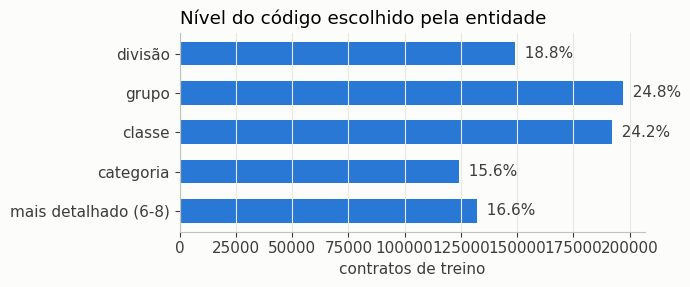

,contratos,pct
nivel,,
divisão,149258,18.8%
grupo,196885,24.8%
classe,192388,24.2%
categoria,124099,15.6%
mais detalhado (6-8),132253,16.6%


In [8]:
niveis = cd.level_name(treino["nivel"]).value_counts()
ordem = ["divisão", "grupo", "classe", "categoria", "mais detalhado (6-8)"]
niveis = niveis.reindex(ordem)

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(niveis.index[::-1], niveis.values[::-1], color=AZUL, height=0.6)
for y, v in enumerate(niveis.values[::-1]):
    ax.text(v, y, f"  {v / len(treino):.1%}", va="center", color="#3d3d3a")
ax.set_xlabel("contratos de treino")
ax.set_title("Nível do código escolhido pela entidade", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

niveis.to_frame("contratos").assign(pct=lambda t: t["contratos"] / len(treino)).style.format({"pct": "{:.1%}"})

In [9]:
treino["divisao"] = treino["codigo"].str[:2]
por_div = treino.groupby("divisao").agg(
    contratos=("codigo", "size"),
    pct_nivel_divisao=("nivel", lambda s: (s == 2).mean()),
    pct_ate_grupo=("nivel", lambda s: (s <= 3).mean()),
    ficam_sem_divisao=("nivel", lambda s: (s > 2).sum()),
).sort_values("contratos", ascending=False)
por_div["pct_do_treino"] = por_div["contratos"] / len(treino)
print("As 10 divisões com mais contratos:")
por_div.head(10).style.format({"pct_nivel_divisao": "{:.1%}", "pct_ate_grupo": "{:.1%}", "pct_do_treino": "{:.1%}"})

As 10 divisões com mais contratos:


,contratos,pct_nivel_divisao,pct_ate_grupo,ficam_sem_divisao,pct_do_treino
divisao,,,,,
33,257682,24.0%,64.6%,195796,32.4%
45,49843,10.4%,16.6%,44663,6.3%
79,49532,8.6%,22.1%,45292,6.2%
50,37795,38.2%,56.5%,23357,4.8%
71,33521,10.7%,26.5%,29927,4.2%
92,31541,22.7%,36.9%,24367,4.0%
72,28159,18.1%,42.7%,23064,3.5%
15,23361,21.1%,57.6%,18431,2.9%
30,22125,15.2%,33.6%,18760,2.8%


In [10]:
print("Divisões que ficam com menos contratos se tirarmos os códigos ao nível da divisão:")
por_div.sort_values("ficam_sem_divisao").head(3)

Divisões que ficam com menos contratos se tirarmos os códigos ao nível da divisão:


,contratos,pct_nivel_divisao,pct_ate_grupo,ficam_sem_divisao,pct_do_treino
divisao,,,,,
41,113,0.654867,0.796460,39,0.000142
76,278,0.582734,0.690647,116,0.000350
70,446,0.112108,0.464126,396,0.000561


In [11]:
print(f"Tirar também os do nível do grupo custaria {(treino['nivel'] <= 3).mean():.1%} do treino")
d33 = treino[treino["divisao"] == "33"]
print(f"... e {(d33['nivel'] <= 3).mean():.1%} da divisão 33")
del d33

Tirar também os do nível do grupo custaria 43.5% do treino
... e 64.6% da divisão 33


**Como ler:**
- Se os genéricos fossem poucos (por exemplo 2%), podíamos ignorá-los. Se forem muitos, temos de decidir o que fazer com eles.
- Um resultado mau seria tirar os genéricos e uma divisão ficar sem contratos.
- Genérico não é o mesmo que errado: às vezes o código geral é a escolha certa.
- **Decisão 8:** no treino, tirar só os códigos ao nível da divisão. Na avaliação, avaliar cada contrato só até ao nível que a etiqueta tem.

## 10. Quantos exemplos tem cada código (desequilíbrio de classes)

**Pergunta:** quantos códigos distintos tem o treino final, e quantos exemplos tem cada um?

**Porque importa:** um modelo não aprende um código com 1 ou 2 exemplos. A decisão 9 diz que um código com menos de N exemplos sobe para a classe ou o grupo. Esta secção mostra quantos códigos ficariam abaixo de cada N.

Aqui já não se usam os contratos, mas os **exemplos de treino** que o `prepare.py` grava (`treino.parquet`): sem códigos ao nível da divisão e com um só exemplo por texto (decisões 6 e 8). É com estes que as contagens da decisão 9 se fazem (`src/labels.py`). A validação vem do `validacao.parquet`, também sem os códigos ao nível da divisão.

In [12]:
del treino  # os contratos já não são precisos; liberta memória
ex = pd.read_parquet(cd.ROOT / "data" / "processed" / "treino.parquet", columns=["codigo", "n_contratos"])
val = pd.read_parquet(cd.ROOT / "data" / "processed" / "validacao.parquet", columns=["codigo", "nivel"])
val_esp = val[val["nivel"] > 2]
print("Exemplos de treino:", len(ex), "(vêm de", ex["n_contratos"].sum(), "contratos)")
print("Contratos de validação:", len(val), "; sem códigos ao nível da divisão:", len(val_esp))

pd.Series({
    "divisão (2)": ex["codigo"].str[:2].nunique(),
    "grupo (3)": ex["codigo"].str[:3].nunique(),
    "classe (4)": ex["codigo"].str[:4].nunique(),
    "código como foi escolhido (8)": ex["codigo"].nunique(),
}).to_frame("códigos distintos no treino")

Exemplos de treino: 478384 (vêm de 645625 contratos)
Contratos de validação: 23945 ; sem códigos ao nível da divisão: 19894


,códigos distintos no treino
divisão (2),45
grupo (3),270
classe (4),1152
código como foi escolhido (8),6071


Mediana de exemplos por código: 8
Códigos com 1 só exemplo: 1026
Código mais comum: 33600000 com 37151 exemplos (7.8% do treino)
Os 10 códigos mais comuns cobrem 21.3% do treino


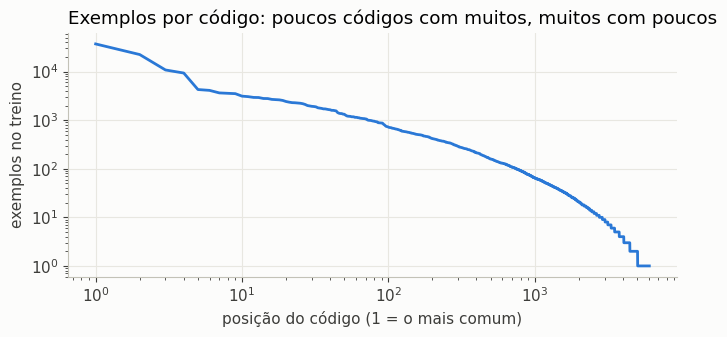

In [13]:
vc = ex["codigo"].value_counts()
print("Mediana de exemplos por código:", int(vc.median()))
print("Códigos com 1 só exemplo:", (vc == 1).sum())
print(f"Código mais comum: {vc.index[0]} com {vc.iloc[0]} exemplos ({vc.iloc[0] / len(ex):.1%} do treino)")
print(f"Os 10 códigos mais comuns cobrem {vc.head(10).sum() / len(ex):.1%} do treino")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(1, len(vc) + 1), vc.values, color=AZUL, linewidth=2)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("posição do código (1 = o mais comum)")
ax.set_ylabel("exemplos no treino")
ax.set_title("Exemplos por código: poucos códigos com muitos, muitos com poucos", loc="left")
plt.tight_layout()
plt.show()

O gráfico usa escala logarítmica nos dois eixos: cada risca vale 10 vezes a anterior. Sem isso, os códigos com milhares de exemplos esmagavam o resto e não se via nada.

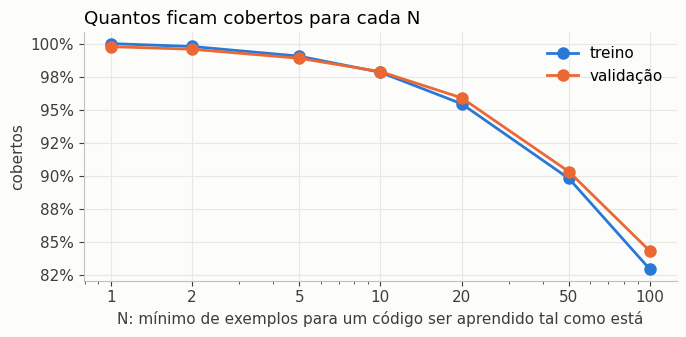

,códigos com pelo menos N,% exemplos de treino,% contratos de validação
N (mínimo de exemplos),,,
1,6071,100.0%,99.8%
2,5045,99.8%,99.6%
5,3778,99.1%,98.9%
10,2896,97.8%,97.9%
20,2063,95.5%,95.9%
50,1220,89.8%,90.3%
100,748,82.9%,84.3%


In [14]:
linhas = []
for n in [1, 2, 5, 10, 20, 50, 100]:
    ficam = vc[vc >= n].index
    linhas.append({
        "N (mínimo de exemplos)": n,
        "códigos com pelo menos N": len(ficam),
        "% exemplos de treino": ex["codigo"].isin(ficam).mean(),
        "% contratos de validação": val_esp["codigo"].isin(ficam).mean(),
    })
cobertura = pd.DataFrame(linhas).set_index("N (mínimo de exemplos)")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(cobertura.index, cobertura["% exemplos de treino"], color=AZUL, linewidth=2, marker="o", markersize=8, label="treino")
ax.plot(cobertura.index, cobertura["% contratos de validação"], color=LARANJA, linewidth=2, marker="o", markersize=8, label="validação")
ax.set_xscale("log")
ax.set_xticks(cobertura.index, [str(n) for n in cobertura.index])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("N: mínimo de exemplos para um código ser aprendido tal como está")
ax.set_ylabel("cobertos")
ax.set_title("Quantos ficam cobertos para cada N", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

cobertura.style.format({"% exemplos de treino": "{:.1%}", "% contratos de validação": "{:.1%}"})

**Como ler:**
- **Desequilíbrio de classes:** metade dos códigos tem poucos exemplos, e poucos códigos têm uma fatia grande do treino. É por isto que vamos medir o F1 macro: com ele, um modelo que só acerta nos códigos comuns tem nota baixa.
- **"% contratos de validação"** responde a: dos contratos novos (outubro), quantos têm um código que o modelo aprende tal como está? É uma estimativa do teto no código completo. Os outros não ficam perdidos: com a decisão 9 o código sobe para a classe ou o grupo, e ainda se pode acertar a esse nível.
- As duas curvas quase coincidem. Isso é bom: o treino representa bem o mês seguinte. Se a validação estivesse muito abaixo do treino, quereria dizer que os códigos mudam muito de mês para mês.
- Com N = 10 dá 97,9%, e o `02_anos_treino.ipynb` dava 98,2% para a mesma janela. Não é uma contradição: lá contavam-se contratos, aqui contam-se exemplos de treino, já com um só exemplo por texto (decisão 6). Um código usado em muitos contratos com o mesmo texto fica com menos exemplos.
- **Por decidir na fase 4:** o valor de N (5, 10 ou 20), escolhido com o TF-IDF na validação.

## Como avaliar este notebook

Perguntas para fazer a qualquer exploração, esta ou outra:

1. **Os números vêm do código?** Cada número do `qualidade_dados.md` tem de sair de uma célula deste notebook ou do `00_qualidade.ipynb`. Se não sair, não está verificado.
2. **Corre de cima para baixo sem erros?** "Run All" num kernel novo. Se só funciona correndo as células noutra ordem, está errado.
3. **Usa só os dados que deve?** Procurar onde se filtra o período. Aqui: a leitura para em outubro, e o `assert` confirma que só ficou o treino.
4. **Os números fazem sentido?** As percentagens somam 100%? Os totais batem com os de outras partes? Aqui há dois controlos: o número de contratos de treino e o número de contratos fora do código mais comum têm de bater com o funil do `prepare.py`. Um número muito bom ou muito mau merece desconfiança antes de festejo.
5. **Cada medição leva a uma decisão?** Se uma medição não muda nada no que vamos fazer, é curiosidade, não exploração.
6. **As decisões estão escritas?** Aqui, no `qualidade_dados.md`. Daqui a um mês ninguém se lembra porque se tirou os códigos ao nível da divisão.